In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from sklearn.decomposition import PCA

print("Library berhasil di-import")

Library berhasil di-import


In [67]:
df_raw = pd.read_csv("dataset_modul2_preprocessing_500.csv")

df_raw.head()

,ID_Mahasiswa,Jenis_Kelamin,Program_Studi,Semester,Kota_Asal,Jumlah_Organisasi,Jam_Belajar_per_Minggu,Kehadiran_Persen,Nilai_Tugas,Nilai_UTS,Nilai_UAS,Uang_Saku_per_Bulan
0,MHS001,Laki-laki,Teknik Komputer,5,Gowa,1,12.0,73.0,80.3,78.2,81.6,1400000
1,MHS002,Laki-laki,Teknik Elektro,1,Bone,0,9.5,76.9,84.6,76.3,76.2,1150000
2,MHS003,Perempuan,Pendidikan Teknik Informatika,5,Gowa,1,12.7,81.3,81.2,72.9,82.1,700000
3,MHS004,Perempuan,Teknik Elektro,1,Takalar,0,11.0,95.8,83.0,85.0,87.9,3250000
4,MHS005,Laki-laki,Pendidikan Teknik Informatika,1,Gowa,2,9.3,91.0,77.7,71.9,88.7,3450000


In [68]:
print("Jumlah Observasi: ", df_raw.shape[0])
print("Jumlah Atribut: ", df_raw.shape[1])
print("Ukuran Dataset: ", df_raw.shape)

Jumlah Observasi:  500
Jumlah Atribut:  12
Ukuran Dataset:  (500, 12)


In [69]:
jumlah_missing = df_raw.isnull().sum()

print(jumlah_missing)

ID_Mahasiswa               0
Jenis_Kelamin              4
Program_Studi              0
Semester                   0
Kota_Asal                  3
Jumlah_Organisasi          0
Jam_Belajar_per_Minggu    10
Kehadiran_Persen           0
Nilai_Tugas                0
Nilai_UTS                  6
Nilai_UAS                  5
Uang_Saku_per_Bulan        0
dtype: int64


In [70]:
jumlah_missing = df_raw.isnull().sum()

print(jumlah_missing[jumlah_missing > 0])

Jenis_Kelamin              4
Kota_Asal                  3
Jam_Belajar_per_Minggu    10
Nilai_UTS                  6
Nilai_UAS                  5
dtype: int64


In [71]:
persentase_missing = (
    df_raw.isnull().sum() / len(df_raw)
).round(2)

ringkasan_missing = pd.DataFrame({
    "Jumlah_Missing": df_raw.isnull().sum(),
    "Persentase_Missing": persentase_missing
})

ringkasan_missing = ringkasan_missing[
    ringkasan_missing["Jumlah_Missing"] > 0
]

ringkasan_missing

,Jumlah_Missing,Persentase_Missing
Jenis_Kelamin,4,0.01
Kota_Asal,3,0.01
Jam_Belajar_per_Minggu,10,0.02
Nilai_UTS,6,0.01
Nilai_UAS,5,0.01


In [72]:
df_drop = df_raw.dropna()

print("Jumlah data sebelum: ", len(df_raw))
print("Jumlah data sesudah: ", len(df_drop))
print("Data yang terhapus: ", len(df_raw) - len(df_drop))

Jumlah data sebelum:  500
Jumlah data sesudah:  472
Data yang terhapus:  28


In [ ]:
df_manual = df_raw.copy()

df_manual["Kota_Asal"] = df_manual["Kota_Asal"].fillna("Pangkep")

print(df_manual["Kota_Asal"].value_counts(dropna = False))

Kota_Asal
Makassar    91
Parepare    87
Gowa        81
Bone        81
Takalar     80
Maros       75
Pangkep      3
makassar     1
GOWA         1
Name: count, dtype: int64


In [74]:
df_mean = df_raw.copy()

mean_jam_belajar = df_mean["Jam_Belajar_per_Minggu"].mean()

df_mean["Jam_Belajar_per_Minggu"] = (
    df_mean["Jam_Belajar_per_Minggu"]
    .fillna(mean_jam_belajar)
)

print("Mean Jam Belajar: ", round(mean_jam_belajar, 2))

print(
    "Missing Value Tersisa: ", df_mean["Jam_Belajar_per_Minggu"].isnull().sum()
)

Mean Jam Belajar:  12.72
Missing Value Tersisa:  0


In [75]:
df_median = df_raw.copy()

median_jam_belajar = df_median["Jam_Belajar_per_Minggu"].median()

df_median["Jam_Belajar_per_Minggu"] = (
    df_median["Jam_Belajar_per_Minggu"]
    .fillna(median_jam_belajar)
)

print("Median Jam Belajar: ", median_jam_belajar)
print("Missing Value Tersisa: ", df_median["Jam_Belajar_per_Minggu"].isnull().sum())

Median Jam Belajar:  12.5
Missing Value Tersisa:  0


In [76]:
df_mode = df_raw.copy()

modus_gender = df_mode["Jenis_Kelamin"].mode()[0]

df_mode["Jenis_Kelamin"] = (
    df_mode["Jenis_Kelamin"]
    .fillna(modus_gender)
)

print("Modus Jenis Kelamin: ", modus_gender)
print(df_mode["Jenis_Kelamin"].value_counts(dropna = False))

Modus Jenis Kelamin:  Laki-laki
Jenis_Kelamin
Laki-laki    265
Perempuan    231
laki laki      1
L              1
PEREMPUAN      1
P              1
Name: count, dtype: int64


In [77]:
from sklearn.impute import KNNImputer

df_knn = df_raw.copy()

fitur_knn = [
    "Jam_Belajar_per_Minggu",
    "Kehadiran_Persen",
    "Nilai_Tugas",
    "Nilai_UTS",
    "Nilai_UAS"
]

imputer = KNNImputer(n_neighbors = 5)

df_knn[fitur_knn] = imputer.fit_transform(
    df_knn[fitur_knn]
)

print(df_knn[fitur_knn].isnull().sum())

Jam_Belajar_per_Minggu    0
Kehadiran_Persen          0
Nilai_Tugas               0
Nilai_UTS                 0
Nilai_UAS                 0
dtype: int64


In [78]:
df = df_raw.copy()

kolom_numerik_missing = [
    "Jam_Belajar_per_Minggu",
    "Nilai_UTS",
    "Nilai_UAS"
]

for kolom in kolom_numerik_missing:
    df[kolom] = df[kolom].fillna(
        df[kolom].median()
    )

kolom_kategorikal_missing = [
    "Jenis_Kelamin",
    "Kota_Asal"
]

for kolom in kolom_kategorikal_missing:
    df[kolom] = df[kolom].fillna(
        df[kolom].mode()[0]
    )

print(
    "Total missing value: ",
    df.isnull().sum().sum()
)

print("\nMissing value per atribut: ")
print(df.isnull().sum())

Total missing value:  0

Missing value per atribut: 
ID_Mahasiswa              0
Jenis_Kelamin             0
Program_Studi             0
Semester                  0
Kota_Asal                 0
Jumlah_Organisasi         0
Jam_Belajar_per_Minggu    0
Kehadiran_Persen          0
Nilai_Tugas               0
Nilai_UTS                 0
Nilai_UAS                 0
Uang_Saku_per_Bulan       0
dtype: int64


In [79]:
jumlah_duplikat = df.duplicated().sum()

print("Jumlah Data Duplikat: ", jumlah_duplikat)

Jumlah Data Duplikat:  5


In [80]:
data_duplikat = df[
    df.duplicated(keep = False)
]

data_duplikat

,ID_Mahasiswa,Jenis_Kelamin,Program_Studi,Semester,Kota_Asal,Jumlah_Organisasi,Jam_Belajar_per_Minggu,Kehadiran_Persen,Nilai_Tugas,Nilai_UTS,Nilai_UAS,Uang_Saku_per_Bulan
20,MHS021,Laki-laki,Teknik Elektro,1,Parepare,1,16.8,87.8,92.7,100.0,98.0,1300000
85,MHS086,Perempuan,Teknik Elektro,5,Makassar,1,18.5,91.1,100.0,88.5,85.5,2850000
170,MHS171,Perempuan,Pendidikan Teknik Informatika,5,Bone,2,18.3,85.8,88.7,92.8,94.1,2200000
260,MHS261,Laki-laki,Pendidikan Teknik Informatika,7,Gowa,1,8.0,73.8,89.9,70.6,72.5,2100000
410,MHS411,Laki-laki,Teknik Komputer,3,Makassar,1,16.7,91.1,87.9,81.4,91.2,1550000
495,MHS021,Laki-laki,Teknik Elektro,1,Parepare,1,16.8,87.8,92.7,100.0,98.0,1300000
496,MHS086,Perempuan,Teknik Elektro,5,Makassar,1,18.5,91.1,100.0,88.5,85.5,2850000
497,MHS171,Perempuan,Pendidikan Teknik Informatika,5,Bone,2,18.3,85.8,88.7,92.8,94.1,2200000
498,MHS261,Laki-laki,Pendidikan Teknik Informatika,7,Gowa,1,8.0,73.8,89.9,70.6,72.5,2100000
499,MHS411,Laki-laki,Teknik Komputer,3,Makassar,1,16.7,91.1,87.9,81.4,91.2,1550000


In [81]:
print("Jumlah data sebelum: ", len(df))

df = (
    df.drop_duplicates()
    .reset_index(drop = True)
)

print("Jumlah data sesudah: ", len(df))
print("Jumlah duplikat tersisa: ", df.duplicated().sum())
print("Total missing value: ", df.isnull().sum().sum())

Jumlah data sebelum:  500
Jumlah data sesudah:  495
Jumlah duplikat tersisa:  0
Total missing value:  0


In [82]:
print(df["Jenis_Kelamin"].value_counts())

Jenis_Kelamin
Laki-laki    262
Perempuan    229
laki laki      1
L              1
PEREMPUAN      1
P              1
Name: count, dtype: int64


In [83]:
mapping_gender = {
    "Laki-laki": "Laki-laki",
    "laki laki": "Laki-laki",
    "L": "Laki-laki",
    "Perempuan": "Perempuan",
    "PEREMPUAN": "Perempuan",
    "P": "Perempuan"
}

df["Jenis_Kelamin"] = df["Jenis_Kelamin"].replace(mapping_gender)

print(df["Jenis_Kelamin"].value_counts())

Jenis_Kelamin
Laki-laki    264
Perempuan    231
Name: count, dtype: int64


In [84]:
print(df["Program_Studi"].value_counts())

Program_Studi
Teknik Elektro                   166
Pendidikan Teknik Informatika    166
Teknik Komputer                  160
teknik komputer                    1
Teknik  Komputer                   1
Pendidikan TI                      1
Name: count, dtype: int64


In [85]:
mapping_prodi = {
    "teknik komputer": "Teknik Komputer",
    "Teknik  Komputer": "Teknik Komputer",
    "Pendidikan TI": "Pendidikan Teknik Informatika"
}

df["Program_Studi"] = df["Program_Studi"].replace(mapping_prodi)

print(df["Program_Studi"].value_counts())

Program_Studi
Pendidikan Teknik Informatika    167
Teknik Elektro                   166
Teknik Komputer                  162
Name: count, dtype: int64


In [86]:
data_binning = (
    df["Nilai_Tugas"]
    .sort_values()
    .head(12)
    .to_numpy()
)

print("Data sebelum smoothing: ")
print(data_binning)

Data sebelum smoothing: 
[52.6 54.8 58.4 58.9 59.5 60.4 60.6 61.2 61.2 61.2 61.7 62.3]


In [87]:
bins = np.array_split(
    data_binning,
    3
)

for i, data_bin in enumerate(bins, start = 1):
    print(f"Bin {i}: {data_bin}")

Bin 1: [52.6 54.8 58.4 58.9]
Bin 2: [59.5 60.4 60.6 61.2]
Bin 3: [61.2 61.2 61.7 62.3]


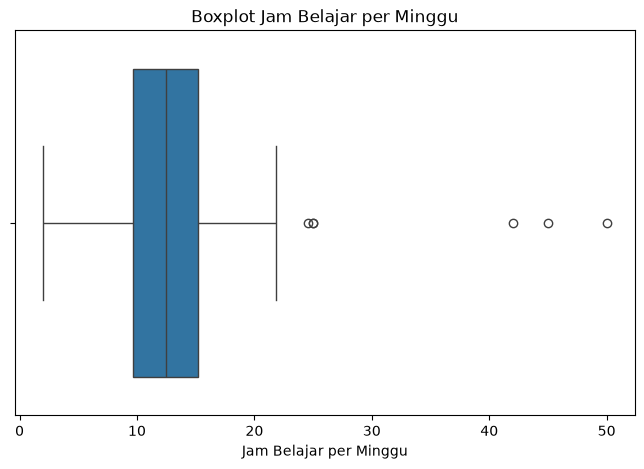

In [88]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data = df,
    x = "Jam_Belajar_per_Minggu"
)

plt.title("Boxplot Jam Belajar per Minggu")
plt.xlabel("Jam Belajar per Minggu")

plt.show()

In [89]:
Q1 = df["Jam_Belajar_per_Minggu"].quantile(0.25)
Q3 = df["Jam_Belajar_per_Minggu"].quantile(0.75)

IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

print("Q1           :", Q1)
print("Q3           :", Q3)
print("IQR          :", IQR)
print("Batas Bawah  :", batas_bawah)
print("Batas Atas   :", batas_atas)

Q1           : 9.7
Q3           : 15.2
IQR          : 5.5
Batas Bawah  : 1.4499999999999993
Batas Atas   : 23.45


In [90]:
outlier_jam_belajar = df[
    (df["Jam_Belajar_per_Minggu"] < batas_bawah) |
    (df["Jam_Belajar_per_Minggu"] > batas_atas)
]

outlier_jam_belajar[
    [
        "ID_Mahasiswa",
        "Jam_Belajar_per_Minggu"
    ]
]

,ID_Mahasiswa,Jam_Belajar_per_Minggu
24,MHS025,45.0
77,MHS078,24.6
95,MHS096,25.0
201,MHS202,50.0
250,MHS251,25.0
366,MHS367,42.0


In [91]:
def deteksi_outlier_iqr(dataframe, kolom):
    Q1 = dataframe[kolom].quantile(0.25)
    Q3 = dataframe[kolom].quantile(0.75)

    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    outlier = dataframe[
        (dataframe[kolom] < batas_bawah) |
        (dataframe[kolom] > batas_atas)
    ]

    return (
        outlier,
        batas_bawah,
        batas_atas
    )

In [92]:
(
    outlier_uang_saku,
    batas_bawah_uang,
    batas_atas_uang,
) = deteksi_outlier_iqr(
    df,
    "Uang_Saku_per_Bulan"
)

print("Batas Bawah:", batas_bawah_uang)
print("Batas Atas:", batas_atas_uang)
print("Jumlah Outlier:", len(outlier_uang_saku))

outlier_uang_saku[
    [
        "ID_Mahasiswa",
        "Uang_Saku_per_Bulan"
    ]
]

Batas Bawah: -950000.0
Batas Atas: 5050000.0
Jumlah Outlier: 2


,ID_Mahasiswa,Uang_Saku_per_Bulan
60,MHS061,15000000
354,MHS355,20000000


In [93]:
mean_jam = df["Jam_Belajar_per_Minggu"].mean()
std_jam = df["Jam_Belajar_per_Minggu"].std()

df_zscore = df.copy()

df_zscore["Z_Score_Jam_Belajar"] = (
    (df_zscore["Jam_Belajar_per_Minggu"] - mean_jam) / std_jam
)

df_zscore[
    [
        "ID_Mahasiswa",
        "Jam_Belajar_per_Minggu",
        "Z_Score_Jam_Belajar"
    ]
].head()

,ID_Mahasiswa,Jam_Belajar_per_Minggu,Z_Score_Jam_Belajar
0,MHS001,12.0,-0.144315
1,MHS002,9.5,-0.673472
2,MHS003,12.7,0.003848
3,MHS004,11.0,-0.355978
4,MHS005,9.3,-0.715804


In [94]:
outlier_zscore = df_zscore[
    df_zscore["Z_Score_Jam_Belajar"].abs() > 3
]

outlier_zscore[
    [
        "ID_Mahasiswa",
        "Jam_Belajar_per_Minggu",
        "Z_Score_Jam_Belajar",
    ]
]

,ID_Mahasiswa,Jam_Belajar_per_Minggu,Z_Score_Jam_Belajar
24,MHS025,45.0,6.840547
201,MHS202,50.0,7.898860
366,MHS367,42.0,6.205560


In [95]:
df_hapus_outliier = df[
    (df["Jam_Belajar_per_Minggu"] >= batas_bawah) &
    (df["Jam_Belajar_per_Minggu"] <= batas_atas)
].copy()

print("Sebelum:", len(df))
print("Sesudah:", len(df_hapus_outliier))

Sebelum: 495
Sesudah: 489


In [96]:
df_capping = df.copy()

Q1 = (
    df_capping["Jam_Belajar_per_Minggu"].quantile(0.25)
)

Q3 = (
    df_capping["Jam_Belajar_per_Minggu"].quantile(0.75)
)

IQR =  Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

df_capping[
    "Jam_Belajar_per_Minggu"
] = (
    df_capping[
        "Jam_Belajar_per_Minggu"
    ]
    .clip(
        lower = batas_bawah,
        upper = batas_atas
    )
)

df_capping[
    "Jam_Belajar_per_Minggu"
].describe()

count    495.000000
mean      12.538586
std        4.016645
min        2.000000
25%        9.700000
50%       12.500000
75%       15.200000
max       23.450000
Name: Jam_Belajar_per_Minggu, dtype: float64

In [97]:
kolom_capping = [
    "Jam_Belajar_per_Minggu",
    "Uang_Saku_per_Bulan"
]
for kolom in kolom_capping:
    Q1 = df[kolom].quantile(0.25)
    Q3 = df[kolom].quantile(0.75)

    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    df[kolom] = df[kolom].clip(
        lower=batas_bawah,
        upper=batas_atas
    )

print(
    df[kolom_capping]
    .describe()
)

       Jam_Belajar_per_Minggu  Uang_Saku_per_Bulan
count              495.000000         4.950000e+02
mean                12.538586         2.045051e+06
std                  4.016645         8.790584e+05
min                  2.000000         5.000000e+05
25%                  9.700000         1.300000e+06
50%                 12.500000         2.100000e+06
75%                 15.200000         2.800000e+06
max                 23.450000         5.050000e+06


In [98]:
print(
    "Jumlah baris:",
    len(df)
)

print(
    "Jumlah duplikat:",
    df.duplicated().sum()
)

print(
    "Total missing value:",
    df.isnull().sum().sum()
)

assert len(df) == 495
assert df.duplicated().sum() == 0
assert df.isnull().sum().sum() == 0

print(
    "QUALITY GATE PASS:"
    " cleaning selesai."
)

Jumlah baris: 495
Jumlah duplikat: 0
Total missing value: 0
QUALITY GATE PASS: cleaning selesai.


In [99]:
data_identitas = df[
    [
        "ID_Mahasiswa",
        "Jenis_Kelamin",
        "Program_Studi",
        "Semester",
        "Kota_Asal"
    ]
].copy()

data_identitas.head()

,ID_Mahasiswa,Jenis_Kelamin,Program_Studi,Semester,Kota_Asal
0,MHS001,Laki-laki,Teknik Komputer,5,Gowa
1,MHS002,Laki-laki,Teknik Elektro,1,Bone
2,MHS003,Perempuan,Pendidikan Teknik Informatika,5,Gowa
3,MHS004,Perempuan,Teknik Elektro,1,Takalar
4,MHS005,Laki-laki,Pendidikan Teknik Informatika,1,Gowa


In [100]:
data_akademik = df[
    [
        "ID_Mahasiswa",
        "Jumlah_Organisasi",
        "Jam_Belajar_per_Minggu",
        "Kehadiran_Persen",
        "Nilai_Tugas",
        "Nilai_UTS",
        "Nilai_UAS",
        "Uang_Saku_per_Bulan"
    ]
].copy()

data_akademik.head()

,ID_Mahasiswa,Jumlah_Organisasi,Jam_Belajar_per_Minggu,Kehadiran_Persen,Nilai_Tugas,Nilai_UTS,Nilai_UAS,Uang_Saku_per_Bulan
0,MHS001,1,12.0,73.0,80.3,78.2,81.6,1400000
1,MHS002,0,9.5,76.9,84.6,76.3,76.2,1150000
2,MHS003,1,12.7,81.3,81.2,72.9,82.1,700000
3,MHS004,0,11.0,95.8,83.0,85.0,87.9,3250000
4,MHS005,2,9.3,91.0,77.7,71.9,88.7,3450000


In [101]:
df_integrasi = pd.merge(
    data_identitas,
    data_akademik,
    on="ID_Mahasiswa",
    how="inner"
)

print("Ukuran hasil integrasi:", df_integrasi.shape)

df_integrasi.head()

Ukuran hasil integrasi: (495, 12)


,ID_Mahasiswa,Jenis_Kelamin,Program_Studi,Semester,Kota_Asal,Jumlah_Organisasi,Jam_Belajar_per_Minggu,Kehadiran_Persen,Nilai_Tugas,Nilai_UTS,Nilai_UAS,Uang_Saku_per_Bulan
0,MHS001,Laki-laki,Teknik Komputer,5,Gowa,1,12.0,73.0,80.3,78.2,81.6,1400000
1,MHS002,Laki-laki,Teknik Elektro,1,Bone,0,9.5,76.9,84.6,76.3,76.2,1150000
2,MHS003,Perempuan,Pendidikan Teknik Informatika,5,Gowa,1,12.7,81.3,81.2,72.9,82.1,700000
3,MHS004,Perempuan,Teknik Elektro,1,Takalar,0,11.0,95.8,83.0,85.0,87.9,3250000
4,MHS005,Laki-laki,Pendidikan Teknik Informatika,1,Gowa,2,9.3,91.0,77.7,71.9,88.7,3450000


In [102]:
print("Jumlah baris :", len(df_integrasi))
print("Jumlah ID unik :", df_integrasi["ID_Mahasiswa"].nunique())
print("Jumlah duplikat ID :", df_integrasi["ID_Mahasiswa"].duplicated().sum())
print("Jumlah missing :", df_integrasi.isnull().sum().sum())

Jumlah baris : 495
Jumlah ID unik : 495
Jumlah duplikat ID : 0
Jumlah missing : 0


In [103]:
df = df_integrasi.copy()

In [104]:
df[
    [
        "Jam_Belajar_per_Minggu",
        "Nilai_UTS",
        "Uang_Saku_per_Bulan"
    ]
].describe()

,Jam_Belajar_per_Minggu,Nilai_UTS,Uang_Saku_per_Bulan
count,495.000000,495.000000,4.950000e+02
mean,12.538586,80.028687,2.045051e+06
std,4.016645,10.612835,8.790584e+05
min,2.000000,50.900000,5.000000e+05
25%,9.700000,73.250000,1.300000e+06
50%,12.500000,79.550000,2.100000e+06
75%,15.200000,86.700000,2.800000e+06
max,23.450000,100.000000,5.050000e+06


In [105]:
from sklearn.preprocessing import MinMaxScaler

fitur_scaling = [
    "Jam_Belajar_per_Minggu",
    "Kehadiran_Persen",
    "Nilai_Tugas",
    "Nilai_UTS",
    "Nilai_UAS",
    "Uang_Saku_per_Bulan"
]

minmax_scaler = MinMaxScaler()

X_minmax = minmax_scaler.fit_transform(
    df[fitur_scaling]
)

df_minmax = pd.DataFrame(
    X_minmax,
    columns=fitur_scaling
)

df_minmax.head()

,Jam_Belajar_per_Minggu,Kehadiran_Persen,Nilai_Tugas,Nilai_UTS,Nilai_UAS,Uang_Saku_per_Bulan
0,0.466200,0.509091,0.584388,0.556008,0.711146,0.197802
1,0.349650,0.580000,0.675105,0.517312,0.626374,0.142857
2,0.498834,0.660000,0.603376,0.448065,0.718995,0.043956
3,0.419580,0.923636,0.641350,0.694501,0.810047,0.604396
4,0.340326,0.836364,0.529536,0.427699,0.822606,0.648352


In [106]:
df_minmax.agg(
    ["min", "max"]
)

,Jam_Belajar_per_Minggu,Kehadiran_Persen,Nilai_Tugas,Nilai_UTS,Nilai_UAS,Uang_Saku_per_Bulan
min,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0


In [107]:
perbandingan_minmax = pd.DataFrame({
    "UTS_Asli": df["Nilai_UTS"].head(),
    "UTS_MinMax": df_minmax["Nilai_UTS"].head(),
    "Uang_Saku_Asli": df["Uang_Saku_per_Bulan"].head(),
    "Uang_Saku_MinMax": df_minmax["Uang_Saku_per_Bulan"].head()
})

perbandingan_minmax

,UTS_Asli,UTS_MinMax,Uang_Saku_Asli,Uang_Saku_MinMax
0,78.2,0.556008,1400000,0.197802
1,76.3,0.517312,1150000,0.142857
2,72.9,0.448065,700000,0.043956
3,85.0,0.694501,3250000,0.604396
4,71.9,0.427699,3450000,0.648352


In [108]:
from sklearn.preprocessing import StandardScaler

standard_scaler = StandardScaler()

X_standard = standard_scaler.fit_transform(
    df[fitur_scaling]
)

df_standard = pd.DataFrame(
    X_standard,
    columns=fitur_scaling
)

df_standard.head()

,Jam_Belajar_per_Minggu,Kehadiran_Persen,Nilai_Tugas,Nilai_UTS,Nilai_UAS,Uang_Saku_per_Bulan
0,-0.134224,-1.437278,-0.185651,-0.172483,0.008766,-0.734539
1,-0.757264,-0.971073,0.260553,-0.351693,-0.497310,-1.019222
2,0.040227,-0.445098,-0.092259,-0.672384,0.055625,-1.531652
3,-0.383440,1.288228,0.094523,0.468898,0.599188,1.372114
4,-0.807107,0.714437,-0.455448,-0.766705,0.674162,1.599860


In [109]:
print("Mean:")
print(df_standard.mean().round(3))

print("\nStandar Deviasi:")
print(df_standard.std(ddof=0).round(3))

Mean:
Jam_Belajar_per_Minggu    0.0
Kehadiran_Persen         -0.0
Nilai_Tugas              -0.0
Nilai_UTS                 0.0
Nilai_UAS                 0.0
Uang_Saku_per_Bulan       0.0
dtype: float64

Standar Deviasi:
Jam_Belajar_per_Minggu    1.0
Kehadiran_Persen          1.0
Nilai_Tugas               1.0
Nilai_UTS                 1.0
Nilai_UAS                 1.0
Uang_Saku_per_Bulan       1.0
dtype: float64


In [110]:
data_decimal = df["Uang_Saku_per_Bulan"].copy()

nilai_maksimum = data_decimal.abs().max()

j = len(str(int(nilai_maksimum)))

hasil_decimal = data_decimal / (10 ** j)

perbandingan_decimal = pd.DataFrame({
    "Uang_Saku_Asli": data_decimal.head(),
    "Decimal_Scaling": hasil_decimal.head()
})

print("Nilai maksimum:", nilai_maksimum)
print("Nilai j:", j)

perbandingan_decimal

Nilai maksimum: 5050000
Nilai j: 7


,Uang_Saku_Asli,Decimal_Scaling
0,1400000,0.140
1,1150000,0.115
2,700000,0.070
3,3250000,0.325
4,3450000,0.345


In [111]:
agregasi_prodi = (
    df.groupby("Program_Studi")
    .agg(
        Jumlah_Mahasiswa=("ID_Mahasiswa", "count"),
        Rata_Jam_Belajar=("Jam_Belajar_per_Minggu", "mean"),
        Rata_Kehadiran=("Kehadiran_Persen", "mean"),
        Rata_UTS=("Nilai_UTS", "mean"),
        Rata_UAS=("Nilai_UAS", "mean")
    )
    .round(2)
)

agregasi_prodi

,Jumlah_Mahasiswa,Rata_Jam_Belajar,Rata_Kehadiran,Rata_UTS,Rata_UAS
Program_Studi,,,,,
Pendidikan Teknik Informatika,167,12.66,85.33,80.12,81.85
Teknik Elektro,166,12.62,85.00,80.27,81.04
Teknik Komputer,162,12.33,84.73,79.69,81.64


In [112]:
df["Nilai_Akhir"] = (
    0.20 * df["Nilai_Tugas"] +
    0.30 * df["Nilai_UTS"] +
    0.50 * df["Nilai_UAS"]
).round(2)

df[
    [
        "Nilai_Tugas",
        "Nilai_UTS",
        "Nilai_UAS",
        "Nilai_Akhir"
    ]
].head(10)

,Nilai_Tugas,Nilai_UTS,Nilai_UAS,Nilai_Akhir
0,80.3,78.2,81.6,80.32
1,84.6,76.3,76.2,77.91
2,81.2,72.9,82.1,79.16
3,83.0,85.0,87.9,86.05
4,77.7,71.9,88.7,81.46
5,94.5,83.0,89.7,88.65
6,88.9,86.0,84.3,85.73
7,61.2,60.6,68.9,64.87
8,81.1,75.4,77.8,77.74
9,81.0,75.8,77.0,77.44


In [113]:
df["Status_Lulus"] = np.where(
    df["Nilai_Akhir"] >= 70,
    "Lulus",
    "Tidak Lulus"
)

df[
    [
        "Nilai_Akhir",
        "Status_Lulus"
    ]
].head(10)

,Nilai_Akhir,Status_Lulus
0,80.32,Lulus
1,77.91,Lulus
2,79.16,Lulus
3,86.05,Lulus
4,81.46,Lulus
5,88.65,Lulus
6,85.73,Lulus
7,64.87,Tidak Lulus
8,77.74,Lulus
9,77.44,Lulus


In [114]:
def kelompok_semester(semester):
    if semester <= 2:
        return "Tingkat Awal"
    elif semester <= 5:
        return "Tingkat Menengah"
    else:
        return "Tingkat Akhir"

df["Tingkat_Studi"] = df["Semester"].apply(
    kelompok_semester
)

df[
    [
        "Semester",
        "Tingkat_Studi"
    ]
].head(15)

,Semester,Tingkat_Studi
0,5,Tingkat Menengah
1,1,Tingkat Awal
2,5,Tingkat Menengah
3,1,Tingkat Awal
4,1,Tingkat Awal
5,3,Tingkat Menengah
6,5,Tingkat Menengah
7,5,Tingkat Menengah
8,1,Tingkat Awal
9,1,Tingkat Awal


In [115]:
print(
    "Jumlah baris:",
    len(df)
)

print(
    "Jumlah kolom:",
    df.shape[1]
)

print(
    "Missing value:",
    df.isnull().sum().sum()
)

print(
    "Duplikat:",
    df.duplicated().sum()
)

assert len(df) == 495
assert df.isnull().sum().sum() == 0
assert df.duplicated().sum() == 0

print(
    "QUALITY GATE PASS:"
    " transformasi valid."
)

Jumlah baris: 495
Jumlah kolom: 15
Missing value: 0
Duplikat: 0
QUALITY GATE PASS: transformasi valid.


In [116]:
fitur_model = [
    "Semester",
    "Jumlah_Organisasi",
    "Jam_Belajar_per_Minggu",
    "Kehadiran_Persen",
    "Nilai_Tugas",
    "Nilai_UTS",
    "Nilai_UAS",
    "Uang_Saku_per_Bulan"
]

X = df[fitur_model].copy()

print("Jumlah atribut dataset:", df.shape[1])
print("Jumlah fitur terpilih :", X.shape[1])

X.head()

Jumlah atribut dataset: 15
Jumlah fitur terpilih : 8


,Semester,Jumlah_Organisasi,Jam_Belajar_per_Minggu,Kehadiran_Persen,Nilai_Tugas,Nilai_UTS,Nilai_UAS,Uang_Saku_per_Bulan
0,5,1,12.0,73.0,80.3,78.2,81.6,1400000
1,1,0,9.5,76.9,84.6,76.3,76.2,1150000
2,5,1,12.7,81.3,81.2,72.9,82.1,700000
3,1,0,11.0,95.8,83.0,85.0,87.9,3250000
4,1,2,9.3,91.0,77.7,71.9,88.7,3450000


In [117]:
fitur_korelasi = [
    "Jumlah_Organisasi",
    "Jam_Belajar_per_Minggu",
    "Kehadiran_Persen",
    "Nilai_Tugas",
    "Nilai_UTS",
    "Nilai_UAS",
    "Nilai_Akhir"
]

matriks_korelasi = df[
    fitur_korelasi
    ].corr()
    
matriks_korelasi.round(2)

,Jumlah_Organisasi,Jam_Belajar_per_Minggu,Kehadiran_Persen,Nilai_Tugas,Nilai_UTS,Nilai_UAS,Nilai_Akhir
Jumlah_Organisasi,1.00,0.00,-0.01,-0.04,0.07,-0.01,0.01
Jam_Belajar_per_Minggu,0.00,1.00,0.04,0.56,0.49,0.48,0.58
Kehadiran_Persen,-0.01,0.04,1.00,0.06,0.07,0.05,0.07
Nilai_Tugas,-0.04,0.56,0.06,1.00,0.63,0.63,0.81
Nilai_UTS,0.07,0.49,0.07,0.63,1.00,0.55,0.81
Nilai_UAS,-0.01,0.48,0.05,0.63,0.55,1.00,0.92
Nilai_Akhir,0.01,0.58,0.07,0.81,0.81,0.92,1.00


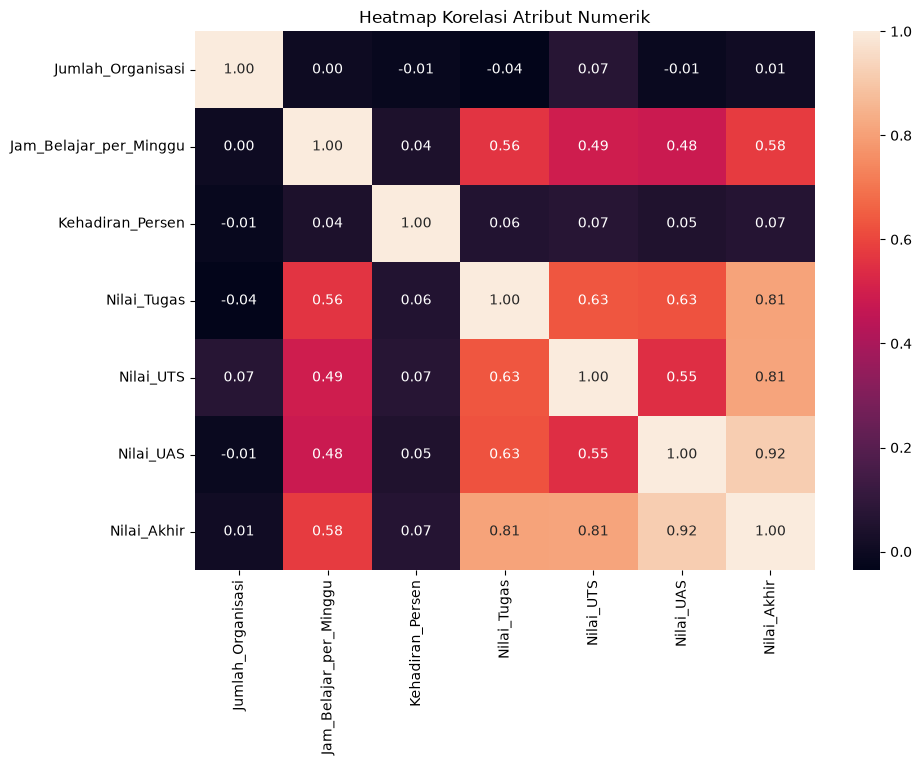

In [118]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    matriks_korelasi,
    annot=True,
    fmt=".2f"
)

plt.title("Heatmap Korelasi Atribut Numerik")

plt.show()

In [119]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

fitur_pca = [
    "Jam_Belajar_per_Minggu",
    "Kehadiran_Persen",
    "Nilai_Tugas",
    "Nilai_UTS",
    "Nilai_UAS",
    "Uang_Saku_per_Bulan"
]

X_pca_awal = (
    df[fitur_pca]
    .copy()
)

scaler_pca = StandardScaler()

X_pca_scaled = (
    scaler_pca.fit_transform(
        X_pca_awal
    )
)

print(
    "Dimensi sebelum PCA:",
    X_pca_scaled.shape
)

Dimensi sebelum PCA: (495, 6)


In [120]:
pca = PCA(
    n_components=2
)

X_pca = pca.fit_transform(
    X_pca_scaled
)

print(
    "Dimensi setelah PCA:",
    X_pca.shape
)

Dimensi setelah PCA: (495, 2)


In [121]:
df_pca = pd.DataFrame(
    X_pca,
    columns=[
        "PC1",
        "PC2"
    ],
    index=df.index
)

df_pca.head()

,PC1,PC2
0,-0.283525,-1.527299
1,-0.629542,-1.368447
2,-0.263554,-1.454061
3,0.390155,1.922281
4,-0.728674,1.618554


In [122]:
sample_random = df.sample(
    frac=0.20,
    random_state=42
)

print("Jumlah data awal :", len(df))
print("Jumlah sampel :", len(sample_random))

sample_random.head()

Jumlah data awal : 495
Jumlah sampel : 99


,ID_Mahasiswa,Jenis_Kelamin,Program_Studi,Semester,Kota_Asal,Jumlah_Organisasi,Jam_Belajar_per_Minggu,Kehadiran_Persen,Nilai_Tugas,Nilai_UTS,Nilai_UAS,Uang_Saku_per_Bulan,Nilai_Akhir,Status_Lulus,Tingkat_Studi
456,MHS457,Perempuan,Teknik Komputer,1,Parepare,1,8.4,91.3,85.8,90.80,100.0,3300000,94.40,Lulus,Tingkat Awal
73,MHS074,Perempuan,Teknik Elektro,7,Takalar,3,20.2,68.6,96.6,94.10,84.2,1850000,89.65,Lulus,Tingkat Akhir
310,MHS311,Laki-laki,Pendidikan Teknik Informatika,5,Parepare,1,12.5,81.4,80.2,85.90,71.3,1200000,77.46,Lulus,Tingkat Menengah
175,MHS176,Perempuan,Teknik Elektro,1,Takalar,1,15.3,85.1,94.5,87.50,81.7,750000,86.00,Lulus,Tingkat Awal
333,MHS334,Perempuan,Teknik Komputer,5,Takalar,2,13.8,88.8,85.5,79.55,78.5,3300000,80.22,Lulus,Tingkat Menengah


In [123]:
df["Kategori_Nilai"] = pd.cut(
    df["Nilai_Akhir"],
    bins=[0, 60, 80, 100],
    labels=[
        "Rendah",
        "Sedang",
        "Tinggi"
    ],
    include_lowest=True
)

df[
    [
        "Nilai_Akhir",
        "Kategori_Nilai"
    ]
].head(15)

,Nilai_Akhir,Kategori_Nilai
0,80.32,Tinggi
1,77.91,Sedang
2,79.16,Sedang
3,86.05,Tinggi
4,81.46,Tinggi
5,88.65,Tinggi
6,85.73,Tinggi
7,64.87,Sedang
8,77.74,Sedang
9,77.44,Sedang


In [124]:
print(
    df["Kategori_Nilai"]
    .value_counts()
    .sort_index()
)

Kategori_Nilai
Rendah      5
Sedang    228
Tinggi    262
Name: count, dtype: int64


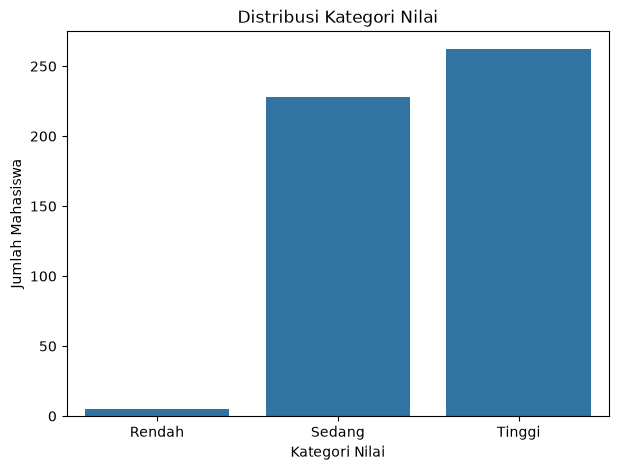

In [125]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Kategori_Nilai",
    order=[
        "Rendah",
        "Sedang",
        "Tinggi"
    ]
)

plt.title("Distribusi Kategori Nilai")
plt.xlabel("Kategori Nilai")
plt.ylabel("Jumlah Mahasiswa")

plt.show()

In [126]:
df["Nilai_Equal_Width"] = pd.cut(
    df["Nilai_Akhir"],
    bins=4
)

print(
    df[
        [
            "Nilai_Akhir",
            "Nilai_Equal_Width"
        ]
    ].head(15)
)

    Nilai_Akhir Nilai_Equal_Width
0         80.32   (74.79, 87.395]
1         77.91   (74.79, 87.395]
2         79.16   (74.79, 87.395]
3         86.05   (74.79, 87.395]
4         81.46   (74.79, 87.395]
5         88.65   (87.395, 100.0]
6         85.73   (74.79, 87.395]
7         64.87   (62.185, 74.79]
8         77.74   (74.79, 87.395]
9         77.44   (74.79, 87.395]
10        76.64   (74.79, 87.395]
11        98.07   (87.395, 100.0]
12        75.56   (74.79, 87.395]
13        86.69   (74.79, 87.395]
14        92.21   (87.395, 100.0]


In [127]:
print(
    df["Nilai_Equal_Width"]
    .value_counts()
    .sort_index()
)

Nilai_Equal_Width
(49.53, 62.185]      8
(62.185, 74.79]    111
(74.79, 87.395]    246
(87.395, 100.0]    130
Name: count, dtype: int64


In [128]:
print("=" * 60)
print("VALIDASI DATASET SETELAH PREPROCESSING")
print("=" * 60)

print("\nUkuran dataset:")
print(df.shape)

print("\nJumlah missing value:")
print(df.isnull().sum())

print("\nTotal missing value:")
print(df.isnull().sum().sum())

print("\nJumlah data duplikat:")
print(df.duplicated().sum())

print("\nJumlah ID unik:")
print(df["ID_Mahasiswa"].nunique())

print("\nKategori Jenis Kelamin:")
print(df["Jenis_Kelamin"].value_counts())

print("\nKategori Program Studi:")
print(df["Program_Studi"].value_counts())

VALIDASI DATASET SETELAH PREPROCESSING

Ukuran dataset:
(495, 17)

Jumlah missing value:
ID_Mahasiswa              0
Jenis_Kelamin             0
Program_Studi             0
Semester                  0
Kota_Asal                 0
Jumlah_Organisasi         0
Jam_Belajar_per_Minggu    0
Kehadiran_Persen          0
Nilai_Tugas               0
Nilai_UTS                 0
Nilai_UAS                 0
Uang_Saku_per_Bulan       0
Nilai_Akhir               0
Status_Lulus              0
Tingkat_Studi             0
Kategori_Nilai            0
Nilai_Equal_Width         0
dtype: int64

Total missing value:
0

Jumlah data duplikat:
0

Jumlah ID unik:
495

Kategori Jenis Kelamin:
Jenis_Kelamin
Laki-laki    264
Perempuan    231
Name: count, dtype: int64

Kategori Program Studi:
Program_Studi
Pendidikan Teknik Informatika    167
Teknik Elektro                   166
Teknik Komputer                  162
Name: count, dtype: int64


In [129]:
ringkasan = pd.DataFrame({
    "Kondisi": [
        "Jumlah Baris",
        "Jumlah Kolom",
        "Total Missing Value",
        "Jumlah Duplikat"
    ],
    "Sebelum": [
        df_raw.shape[0],
        df_raw.shape[1],
        df_raw.isnull().sum().sum(),
        df_raw.duplicated().sum()
    ],
    "Sesudah": [
        df.shape[0],
        df.shape[1],
        df.isnull().sum().sum(),
        df.duplicated().sum()
    ]
})

ringkasan

,Kondisi,Sebelum,Sesudah
0,Jumlah Baris,500,495
1,Jumlah Kolom,12,17
2,Total Missing Value,28,0
3,Jumlah Duplikat,5,0


In [130]:
df.to_csv(
    "dataset_modul2_hasil_preprocessing.csv",
    index=False
)

print(
    "Dataset berhasil disimpan sebagai "
    "dataset_modul2_hasil_preprocessing.csv"
)

Dataset berhasil disimpan sebagai dataset_modul2_hasil_preprocessing.csv
